In [1]:
# System
!apt-get update -qq
!apt-get install -y -qq tesseract-ocr tesseract-ocr-ara tesseract-ocr-fra poppler-utils

# Python
!pip install -q easyocr pytesseract pdf2image pymupdf Pillow opencv-python-headless matplotlib pandas numpy jiwer rapidfuzz

print("Installation complete.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package poppler-utils.
(Reading database ... 122363 files and directories currently installed.)
Preparing to unpack .../poppler-utils_22.02.0-2ubuntu0.12_amd64.deb ...
Unpacking poppler-utils (22.02.0-2ubuntu0.12) ...
Selecting previously unselected package tesseract-ocr-ara.
Preparing to unpack .../tesseract-ocr-ara_1%3a4.00~git30-7274cfa-1.1_all.deb ...
Unpacking tesseract-ocr-ara (1:4.00~git30-7274cfa-1.1) ...
Selecting previously unselected package tesseract-ocr-fra.
Preparing to unpack .../tesseract-ocr-fra_1%3a4.00~git30-7274cfa-1.1_all.deb ...
Unpacking tesseract-ocr-fra (1:4.00~git30-7274cfa-1.1) ...
Setting up tesseract-ocr-ara (1:4.00~git30-7274cfa-1.1) ...
Setting up tesseract-ocr-fra (1:4.00~git30-7274cfa-1.1) ...
Setting up poppler-utils (22.02.0-2ubuntu0.

In [3]:
import pytesseract
import easyocr
import torch
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pdf2image import convert_from_path
from pathlib import Path
from google.colab import files
import cv2

# Check GPU
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    # print(f"VRAM: {torch.cuda.get_device_properties(0).total_mem / 1024**3:.1f} GB")
else:
    print("Running on CPU")

# Tesseract config
TESS_CONFIG = r'--oem 3 --psm 6 -l ara+fra'

print("\nReady.")

CUDA: True
GPU: Tesla T4

Ready.


In [4]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [5]:
TEST_DIR = Path("/content/drive/MyDrive/Data Legal/test")
TEST_DIR.mkdir(exist_ok=True)

print("Upload your Moroccan legal PDFs (at least 3):")
print("  1. A digital/native PDF")
print("  2. A scanned/image-only PDF")
print("  3. A mixed or low-quality PDF")
print()

# uploaded = files.upload()

# for filename, content in uploaded.items():
#     dest = TEST_DIR / filename
#     with open(dest, "wb") as f:
#         f.write(content)
#     print(f"Saved: {filename}")

pdf_files = sorted(TEST_DIR.glob("*.pdf"))
print(f"\nFiles ready: {len(pdf_files)}")
for f in pdf_files:
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name} ({size_kb:.1f} KB)")

Upload your Moroccan legal PDFs (at least 3):
  1. A digital/native PDF
  2. A scanned/image-only PDF
  3. A mixed or low-quality PDF


Files ready: 4
  Livret 2.pdf (11035.8 KB)
  code_route.pdf (1220.5 KB)
  ظهير شريف رقم 1.10.07 صادر في 26 من صفر 1431 (11 فبراير 2010) بتنفيذ القانون رقم 52.05 المتعلق بمدونة السير على الطرق.pdf (2038.7 KB)
  مدونة الأسرة1.pdf (827.5 KB)


Converting: Livret 2.pdf
  3 pages
Converting: code_route.pdf
  3 pages
Converting: ظهير شريف رقم 1.10.07 صادر في 26 من صفر 1431 (11 فبراير 2010) بتنفيذ القانون رقم 52.05 المتعلق بمدونة السير على الطرق.pdf
  3 pages
Converting: مدونة الأسرة1.pdf
  3 pages

Total test pages: 12


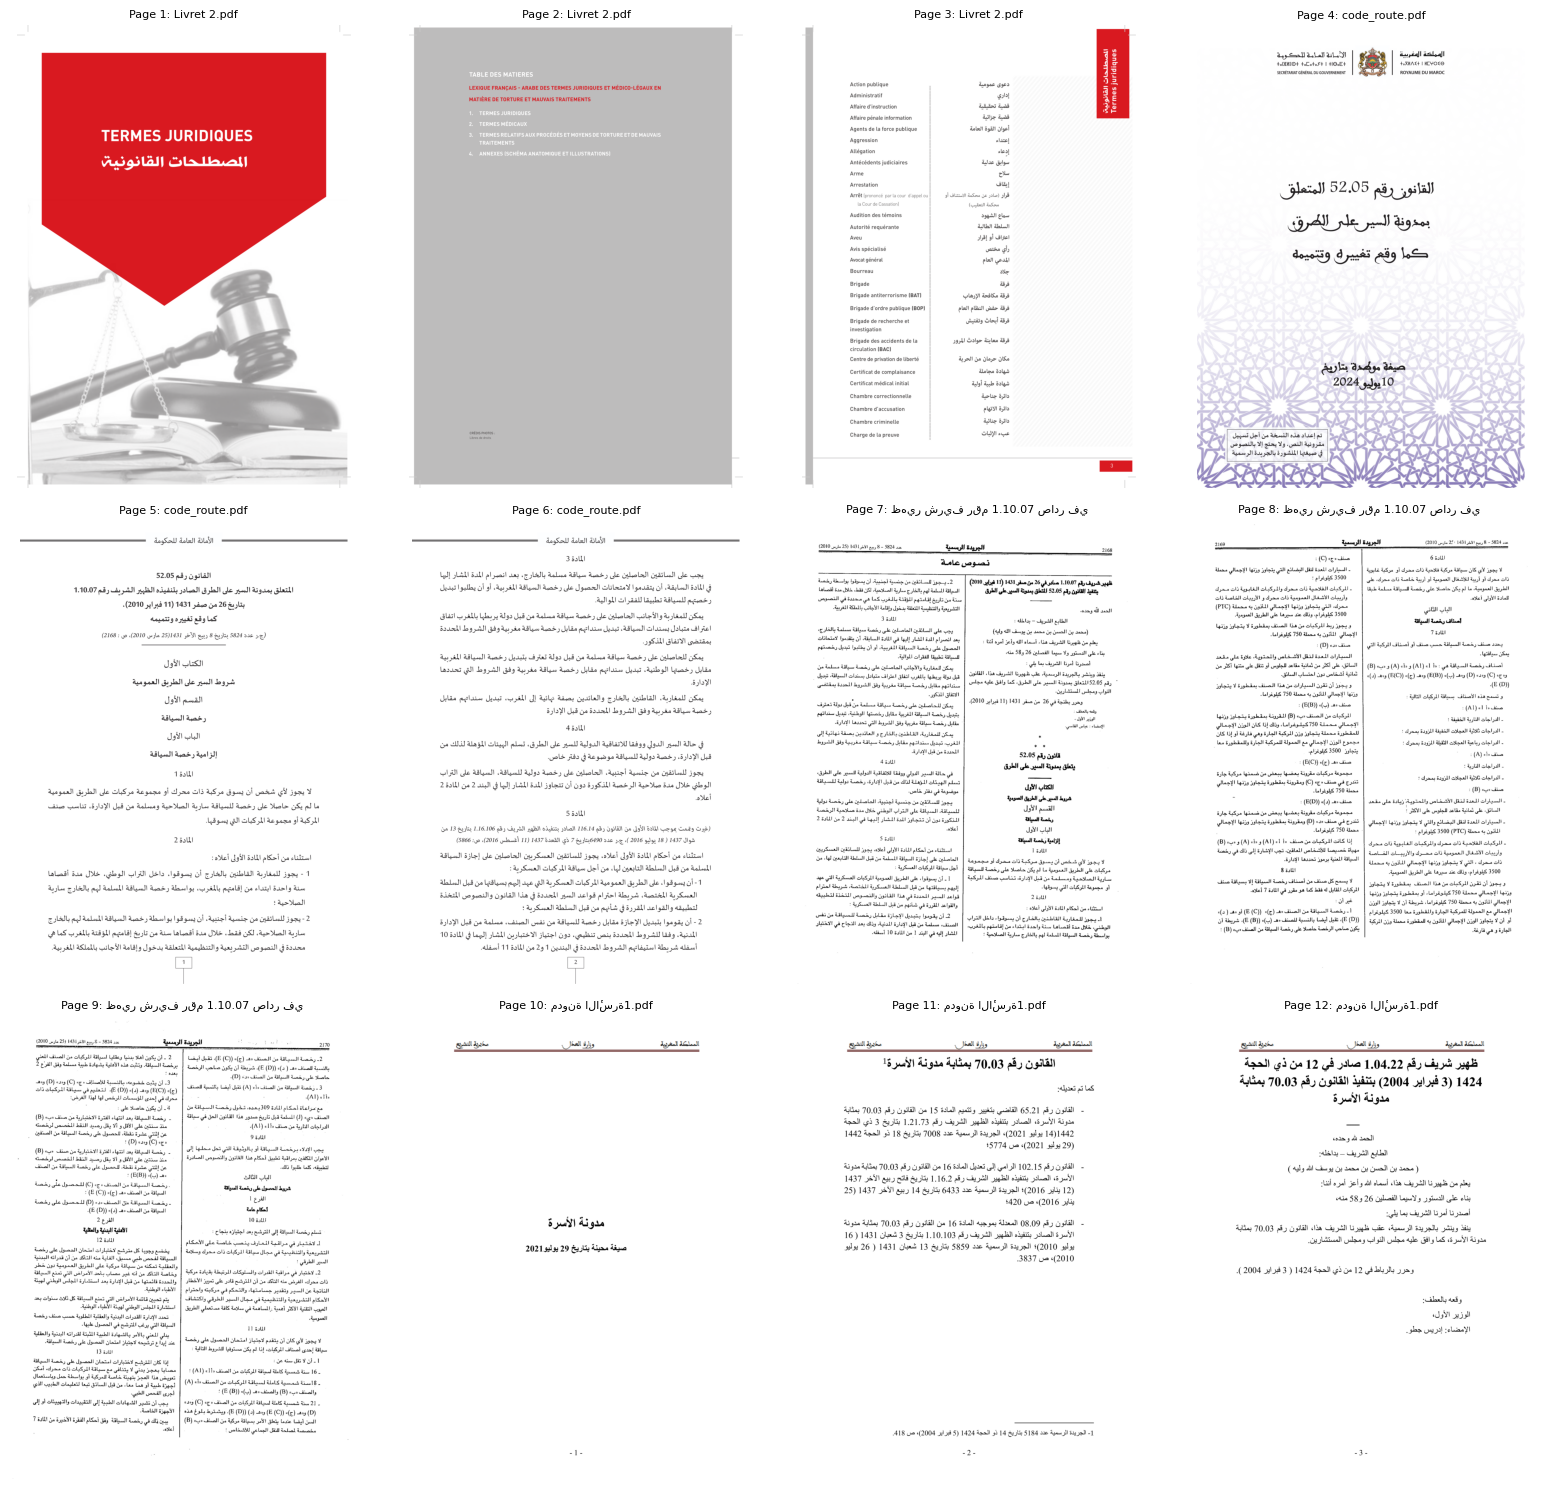

In [6]:
test_pages = []

for pdf_path in pdf_files:
    print(f"Converting: {pdf_path.name}")
    try:
        images = convert_from_path(pdf_path, dpi=300, first_page=1, last_page=3)
        for i, img in enumerate(images):
            test_pages.append({
                "source": pdf_path.name,
                "page_num": i + 1,
                "image": img,
            })
        print(f"  {len(images)} pages")
    except Exception as e:
        print(f"  Error: {e}")

print(f"\nTotal test pages: {len(test_pages)}")

# Show them
n = len(test_pages)
cols = min(n, 4)
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*5))
if rows == 1 and cols == 1:
    axes = [axes]
axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]

for i, page in enumerate(test_pages):
    axes[i].imshow(page["image"])
    axes[i].set_title(f"Page {i+1}: {page['source'][:30]}", fontsize=8)
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [7]:
def preprocess_adaptive(pil_image):
    """Adaptive threshold - best for scanned documents."""
    img = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2GRAY)
    denoised = cv2.fastNlMeansDenoising(img, h=10)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = clahe.apply(denoised)
    binary = cv2.adaptiveThreshold(enhanced, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 10)
    return Image.fromarray(binary)

def preprocess_otsu(pil_image):
    """OTSU binarization - good for clean documents."""
    img = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2GRAY)
    denoised = cv2.fastNlMeansDenoising(img, h=10)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = clahe.apply(denoised)
    _, binary = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return Image.fromarray(binary)

def correct_ocr_text(text):
    """Fix common Arabic OCR errors."""
    if not text:
        return ""
    text = re.sub(r'[\u200b-\u200f\u202a-\u202e\u2060-\u2069]', '', text)
    text = re.sub(r'[أإآ]', 'ا', text)
    text = re.sub(r'ـ+', '', text)
    text = re.sub(r'\s+', ' ', text)
    lines = text.split('\n')
    cleaned = []
    for line in lines:
        s = line.strip()
        if not s:
            continue
        meaningful = sum(1 for c in s if c.isalpha())
        if len(s) > 0 and meaningful / len(s) < 0.2:
            continue
        cleaned.append(line)
    return '\n'.join(cleaned).strip()

print("Preprocessing functions ready.")

Preprocessing functions ready.


In [9]:
print("Initializing EasyOCR...")
easy_start = time.time()
easy_reader = easyocr.Reader(lang_list=["ar","fa","ur","ug","en"], gpu=torch.cuda.is_available())
print(f"EasyOCR ready in {time.time() - easy_start:.1f}s")

print("\nInitializing Tesseract...")
print(f"Tesseract version: {pytesseract.get_tesseract_version()}")
print(f"Languages: {pytesseract.get_languages()}")

Initializing EasyOCR...
Progress: |██████████████████████████████████████████████████| 100.0% CompleteEasyOCR ready in 8.5s

Initializing Tesseract...
Tesseract version: 4.1.1
Languages: ['ara', 'eng', 'fra', 'osd']


In [10]:
results = []

for i, page in enumerate(test_pages):
    print(f"\nPage {i+1}: {page['source'][:50]} (p{page['page_num']})")
    img = page["image"]
    img_array = np.array(img)

    row = {
        "page": i+1,
        "source": page["source"][:40],
        "page_num": page["page_num"],
        "image_size": f"{img.size[0]}x{img.size[1]}",
    }

    # ----- TESSERACT (Adaptive Threshold) -----
    img_adaptive = preprocess_adaptive(img)
    start = time.time()
    tess_adaptive_text = pytesseract.image_to_string(img_adaptive, config=TESS_CONFIG)
    tess_adaptive_time = time.time() - start
    tess_adaptive_text = correct_ocr_text(tess_adaptive_text)

    row["tess_adaptive_chars"] = len(tess_adaptive_text)
    row["tess_adaptive_time"] = round(tess_adaptive_time, 2)
    arabic = sum(1 for c in tess_adaptive_text if '\u0600' <= c <= '\u06ff')
    row["tess_adaptive_arabic"] = arabic

    print(f"  Tesseract (Adaptive): {row['tess_adaptive_chars']} chars, {arabic} Arabic, {tess_adaptive_time:.1f}s")

    # ----- TESSERACT (OTSU) -----
    img_otsu = preprocess_otsu(img)
    start = time.time()
    tess_otsu_text = pytesseract.image_to_string(img_otsu, config=TESS_CONFIG)
    tess_otsu_time = time.time() - start
    tess_otsu_text = correct_ocr_text(tess_otsu_text)

    row["tess_otsu_chars"] = len(tess_otsu_text)
    row["tess_otsu_time"] = round(tess_otsu_time, 2)
    arabic = sum(1 for c in tess_otsu_text if '\u0600' <= c <= '\u06ff')
    row["tess_otsu_arabic"] = arabic

    print(f"  Tesseract (OTSU):     {row['tess_otsu_chars']} chars, {arabic} Arabic, {tess_otsu_time:.1f}s")

    # ----- EASYOCR -----
    start = time.time()
    easy_results = easy_reader.readtext(img_array)
    easy_time = time.time() - start
    easy_text = "\n".join([item[1] for item in easy_results])
    easy_text = correct_ocr_text(easy_text)
    easy_conf = np.mean([item[2] for item in easy_results]) * 100 if easy_results else 0

    row["easy_chars"] = len(easy_text)
    row["easy_time"] = round(easy_time, 2)
    row["easy_conf"] = round(easy_conf, 1)
    arabic = sum(1 for c in easy_text if '\u0600' <= c <= '\u06ff')
    row["easy_arabic"] = arabic

    print(f"  EasyOCR:              {row['easy_chars']} chars, {arabic} Arabic, {easy_time:.1f}s, {easy_conf:.0f}% conf")

    results.append(row)

df = pd.DataFrame(results)
print("\n" + "=" * 60)
print("OCR COMPLETE")


Page 1: Livret 2.pdf (p1)
  Tesseract (Adaptive): 216 chars, 26 Arabic, 3.8s
  Tesseract (OTSU):     69 chars, 18 Arabic, 1.6s
  EasyOCR:              38 chars, 17 Arabic, 2.0s, 50% conf

Page 2: Livret 2.pdf (p2)
  Tesseract (Adaptive): 327 chars, 0 Arabic, 2.8s
  Tesseract (OTSU):     177 chars, 6 Arabic, 3.1s
  EasyOCR:              319 chars, 0 Arabic, 1.9s, 76% conf

Page 3: Livret 2.pdf (p3)
  Tesseract (Adaptive): 1128 chars, 323 Arabic, 10.0s
  Tesseract (OTSU):     1174 chars, 341 Arabic, 9.5s
  EasyOCR:              1050 chars, 340 Arabic, 4.0s, 72% conf

Page 4: code_route.pdf (p1)
  Tesseract (Adaptive): 446 chars, 139 Arabic, 8.3s
  Tesseract (OTSU):     240 chars, 132 Arabic, 5.1s
  EasyOCR:              348 chars, 201 Arabic, 2.1s, 54% conf

Page 5: code_route.pdf (p2)
  Tesseract (Adaptive): 755 chars, 567 Arabic, 3.9s
  Tesseract (OTSU):     793 chars, 597 Arabic, 5.1s
  EasyOCR:              1012 chars, 790 Arabic, 3.5s, 73% conf

Page 6: code_route.pdf (p3)
  Tesser

In [11]:
print("=" * 80)
print("OCR ENGINE COMPARISON - RAW RESULTS")
print("=" * 80)
print(df[["page", "source", "image_size",
          "tess_adaptive_chars", "tess_adaptive_arabic", "tess_adaptive_time",
          "easy_chars", "easy_arabic", "easy_time", "easy_conf"]].to_string(index=False))

# Totals
print("\n" + "=" * 80)
print("TOTALS")
print("=" * 80)
print(f"Tesseract Adaptive: {df['tess_adaptive_arabic'].sum()} Arabic chars, {df['tess_adaptive_time'].sum():.1f}s total")
print(f"Tesseract OTSU:     {df['tess_otsu_arabic'].sum()} Arabic chars, {df['tess_otsu_time'].sum():.1f}s total")
print(f"EasyOCR:            {df['easy_arabic'].sum()} Arabic chars, {df['easy_time'].sum():.1f}s total")

# Best per page
print("\n" + "=" * 80)
print("BEST ENGINE PER PAGE (by Arabic character count)")
print("=" * 80)
for _, row in df.iterrows():
    engines = {
        "Tesseract Adaptive": row["tess_adaptive_arabic"],
        "Tesseract OTSU": row["tess_otsu_arabic"],
        "EasyOCR": row["easy_arabic"],
    }
    best = max(engines, key=engines.get)
    print(f"  Page {int(row['page'])}: {best} ({engines[best]} Arabic chars)")

OCR ENGINE COMPARISON - RAW RESULTS
 page                                   source image_size  tess_adaptive_chars  tess_adaptive_arabic  tess_adaptive_time  easy_chars  easy_arabic  easy_time  easy_conf
    1                             Livret 2.pdf  2656x3683                  216                    26                3.77          38           17       1.99       49.9
    2                             Livret 2.pdf  2656x3683                  327                     0                2.83         319            0       1.88       76.4
    3                             Livret 2.pdf  2656x3683                 1128                   323               10.02        1050          340       3.98       71.8
    4                           code_route.pdf  2484x3509                  446                   139                8.25         348          201       2.08       54.3
    5                           code_route.pdf  2484x3509                  755                   567                3.95    

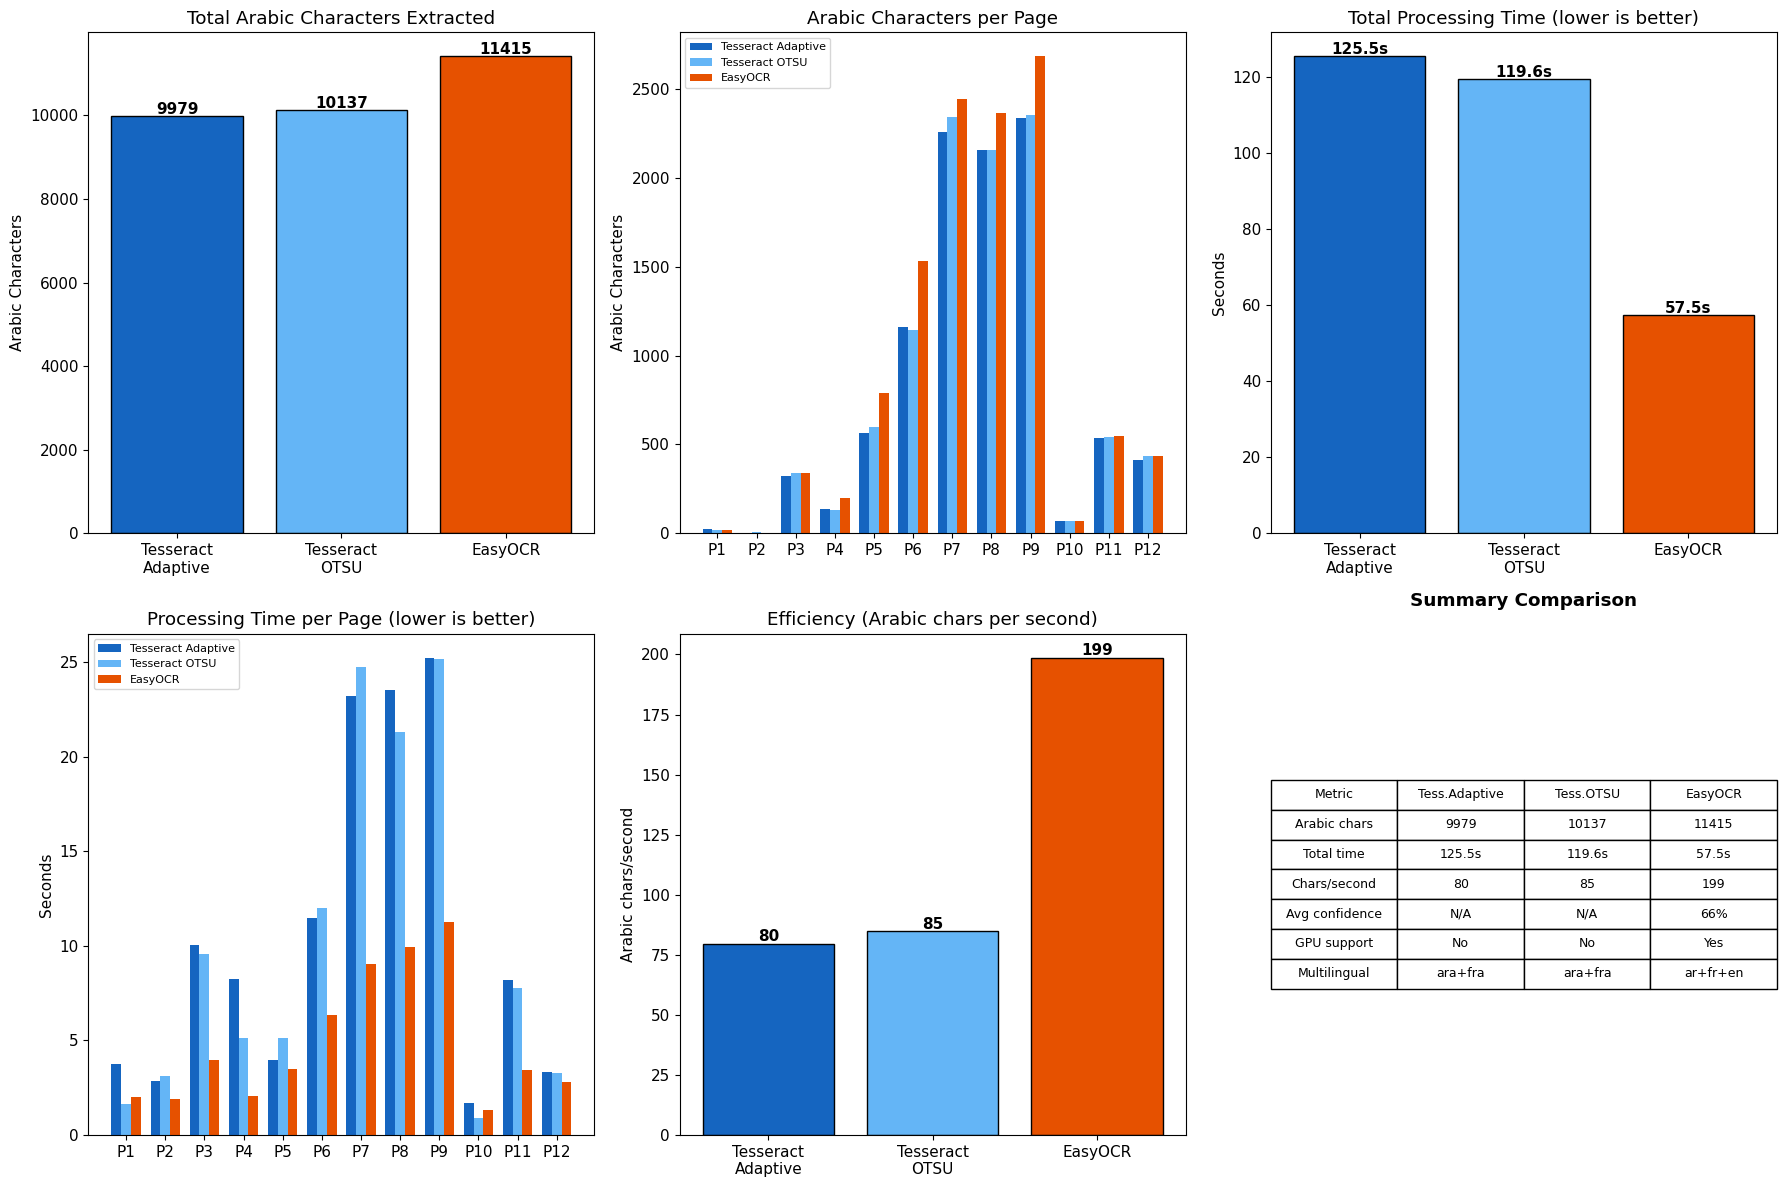

In [13]:
plt.rcParams.update({'font.size': 11})

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1: Total Arabic characters per engine (bar)
ax = axes[0, 0]
totals = {
    "Tesseract\nAdaptive": df["tess_adaptive_arabic"].sum(),
    "Tesseract\nOTSU": df["tess_otsu_arabic"].sum(),
    "EasyOCR": df["easy_arabic"].sum(),
}
colors = ["#1565C0", "#64B5F6", "#E65100"]
bars = ax.bar(totals.keys(), totals.values(), color=colors, edgecolor='black')
ax.set_ylabel("Arabic Characters")
ax.set_title("Total Arabic Characters Extracted")
for bar, val in zip(bars, totals.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, str(val), ha='center', fontweight='bold')

# 2: Per-page Arabic chars (grouped bar)
ax = axes[0, 1]
x = np.arange(len(df))
width = 0.25
ax.bar(x - width, df["tess_adaptive_arabic"], width, label="Tesseract Adaptive", color="#1565C0")
ax.bar(x, df["tess_otsu_arabic"], width, label="Tesseract OTSU", color="#64B5F6")
ax.bar(x + width, df["easy_arabic"], width, label="EasyOCR", color="#E65100")
ax.set_xticks(x)
ax.set_xticklabels([f"P{int(r['page'])}" for _, r in df.iterrows()])
ax.set_ylabel("Arabic Characters")
ax.set_title("Arabic Characters per Page")
ax.legend(fontsize=8)

# 3: Total time per engine
ax = axes[0, 2]
times = {
    "Tesseract\nAdaptive": df["tess_adaptive_time"].sum(),
    "Tesseract\nOTSU": df["tess_otsu_time"].sum(),
    "EasyOCR": df["easy_time"].sum(),
}
bars = ax.bar(times.keys(), times.values(), color=colors, edgecolor='black')
ax.set_ylabel("Seconds")
ax.set_title("Total Processing Time (lower is better)")
for bar, val in zip(bars, times.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f"{val:.1f}s", ha='center', fontweight='bold')

# 4: Per-page time comparison
ax = axes[1, 0]
x = np.arange(len(df))
ax.bar(x - width, df["tess_adaptive_time"], width, label="Tesseract Adaptive", color="#1565C0")
ax.bar(x, df["tess_otsu_time"], width, label="Tesseract OTSU", color="#64B5F6")
ax.bar(x + width, df["easy_time"], width, label="EasyOCR", color="#E65100")
ax.set_xticks(x)
ax.set_xticklabels([f"P{int(r['page'])}" for _, r in df.iterrows()])
ax.set_ylabel("Seconds")
ax.set_title("Processing Time per Page (lower is better)")
ax.legend(fontsize=8)

# 5: Efficiency (Arabic chars per second)
ax = axes[1, 1]
efficiency = {
    "Tesseract\nAdaptive": df["tess_adaptive_arabic"].sum() / df["tess_adaptive_time"].sum(),
    "Tesseract\nOTSU": df["tess_otsu_arabic"].sum() / df["tess_otsu_time"].sum(),
    "EasyOCR": df["easy_arabic"].sum() / df["easy_time"].sum(),
}
bars = ax.bar(efficiency.keys(), efficiency.values(), color=colors, edgecolor='black')
ax.set_ylabel("Arabic chars/second")
ax.set_title("Efficiency (Arabic chars per second)")
for bar, val in zip(bars, efficiency.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f"{val:.0f}", ha='center', fontweight='bold')

# 6: Radar-like comparison table
ax = axes[1, 2]
ax.axis('off')
# Build comparison text
table_data = [
    ["Metric", "Tess.Adaptive", "Tess.OTSU", "EasyOCR"],
    ["Arabic chars", str(df['tess_adaptive_arabic'].sum()), str(df['tess_otsu_arabic'].sum()), str(df['easy_arabic'].sum())],
    ["Total time", f"{df['tess_adaptive_time'].sum():.1f}s", f"{df['tess_otsu_time'].sum():.1f}s", f"{df['easy_time'].sum():.1f}s"],
    ["Chars/second", f"{efficiency['Tesseract\nAdaptive']:.0f}", f"{efficiency['Tesseract\nOTSU']:.0f}", f"{efficiency['EasyOCR']:.0f}"],
    ["Avg confidence", "N/A", "N/A", f"{df['easy_conf'].mean():.0f}%"],
    ["GPU support", "No", "No", "Yes"],
    ["Multilingual", "ara+fra", "ara+fra", "ar+fr+en"],
]
table = ax.table(cellText=table_data, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.0, 1.5)
ax.set_title("Summary Comparison", fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

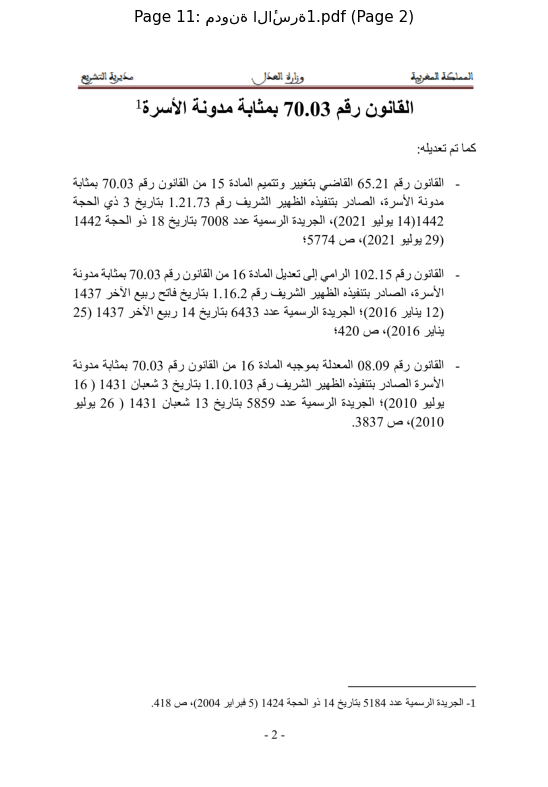

TESSERACT (Adaptive Threshold) - 901 chars, 536 Arabic
المملكة المغريبة JS db مكيرية التشريع القانون رقم 70.03 بمثابة مدونة الاسرة1 كما تم تعديله: - القانون رقم 65.21 القاضي بتغيير وتتميم المادة 15 من القانون رقم 70.03 بمثابة مدونة الاسرة» الصادر بتنفيذه الظهير الشريف رقم 1.21.73 بتاريخ 3 ذي الحجة 2 يوليو 22021)» الجريدة الرسمية عدد 7008 بتاريخ 18 ذو الحجة 1442 (29 يوليو 2021)» ص 5774؛ - القانون رقم 102.15 الرامي الى تعديل المادة 16 من القانون رقم 70.03 بمثابة مدونة الاسرة» الصادر بتنفيذه الظهير الشريف رقم 1.16.2 بتاريخ فاتح ربيع الاخر 1437 (12 يناير 2016)؛ الجريدة الرسمية عدد 6433 بتاريخ 14 ربيع الاخر 1437 (25 يناير 2016)» ص 420؛ - القانون رقم 08
... (301 more chars)

EASYOCR - 886 chars, 548 Arabic
معیریا وزارة العذل المملكا لمغرييا الاسرة1 القانون رقم 70٠03 بمثابة کما تم تعدیلہ : المادة 15 من القانون رقم 7003 بمثابة و بتغيير القانون رقم 65.21 3 ذي الحجۃ الصادر بتنفيذه الظهير الشريف رقم 12173 1442)14 يوليو 2021، الجريدة الرسمية عدد 7008 بتاريخ 18 ذو الحجة 1442 ص 5774: )29 يوليو 2021(

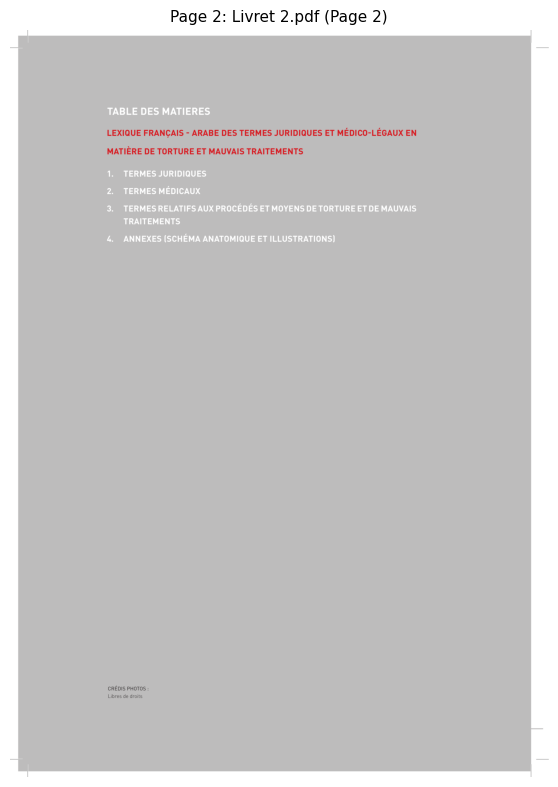

TESSERACT (Adaptive Threshold) - 327 chars, 0 Arabic
VAE OS CAES LEXIQUE FRANCAIS - ARABE DES TERMES JURIDIQUES ET MÉDICO-LÉGAUX EN MATIÈRE DE TORTURE ET MAUVAIS TRAITEMENTS TALERME SYJURIDIQUES) PBTERMESIMEDICAUX SATERMESRELATIES AUXIPROCEDES'ENMOYENS'DEILORLUREIENDEIMAUVAIS) LRALTEMENTS) + 2 201137133 33713714 57153711717113 37 110137305113112 CRÉDIS PHOTOS : Libres de droits

EASYOCR - 319 chars, 0 Arabic
TABLE DES MATIERES LEXIQUE FRANCAIS ARABE DES TERMES JURIDIQUES ET MEDICO-LEGAUX EN MATIERE DE TORTURE ET MAUVAIS TRAITEMENTS 1 TERMES JURIDIQUES 2 TERMES MEDICAUX 3 TERMES RELATIFS AUX PROCEDES ET MOYENS DE TORTURE ET DE MAUVAIS TRAITEMENTS / ANNEXES ISCHEMA ANATOMIQUE ET ILLUSTRATIONSI CREDIS PHOTOS Libres de droits




In [15]:
import random

# Pick 2 random pages to show
random.seed(42)
sample_indices = random.sample(range(len(test_pages)), min(2, len(test_pages)))

for idx in sample_indices:
    page = test_pages[idx]

    # Run both engines
    img_adaptive = preprocess_adaptive(page["image"])
    tess_text = pytesseract.image_to_string(img_adaptive, config=TESS_CONFIG)
    tess_text = correct_ocr_text(tess_text)

    easy_results = easy_reader.readtext(np.array(page["image"]))
    easy_text = "\n".join([item[1] for item in easy_results])
    easy_text = correct_ocr_text(easy_text)

    # Show the image
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(page["image"])
    ax.set_title(f"Page {idx+1}: {page['source'][:60]} (Page {page['page_num']})", fontsize=11)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Print Tesseract output
    tess_arabic = sum(1 for c in tess_text if '\u0600' <= c <= '\u06ff')
    print("=" * 80)
    print(f"TESSERACT (Adaptive Threshold) - {len(tess_text)} chars, {tess_arabic} Arabic")
    print("=" * 80)
    print(tess_text[:600])
    if len(tess_text) > 600:
        print(f"... ({len(tess_text) - 600} more chars)")

    # Print EasyOCR output
    easy_arabic = sum(1 for c in easy_text if '\u0600' <= c <= '\u06ff')
    print()
    print("=" * 80)
    print(f"EASYOCR - {len(easy_text)} chars, {easy_arabic} Arabic")
    print("=" * 80)
    print(easy_text[:600])
    if len(easy_text) > 600:
        print(f"... ({len(easy_text) - 600} more chars)")

    print()
    print()

In [16]:
tess_adaptive_arabic = df["tess_adaptive_arabic"].sum()
tess_otsu_arabic = df["tess_otsu_arabic"].sum()
easy_arabic = df["easy_arabic"].sum()
tess_adaptive_time = df["tess_adaptive_time"].sum()
easy_time = df["easy_time"].sum()
easy_avg_conf = df["easy_conf"].mean()

# Determine winner by Arabic char count
results = {
    "Tesseract (Adaptive Threshold)": (tess_adaptive_arabic, tess_adaptive_time),
    "Tesseract (OTSU)": (tess_otsu_arabic, df["tess_otsu_time"].sum()),
    "EasyOCR": (easy_arabic, easy_time),
}

winner = max(results, key=lambda k: results[k][0])
winner_arabic, winner_time = results[winner]

# Runner up
others = {k: v for k, v in results.items() if k != winner}
runner_up = max(others, key=lambda k: others[k][0])
runner_arabic, runner_time = others[runner_up]

# Efficiency
winner_eff = winner_arabic / winner_time if winner_time > 0 else 0
runner_eff = runner_arabic / runner_time if runner_time > 0 else 0

print("=" * 80)
print("FINAL RECOMMENDATION")
print("=" * 80)

print(f"""
RECOMMENDED ENGINE: {winner}

Why:
  - Extracted {winner_arabic} Arabic characters (vs {runner_up}: {runner_arabic})
  - Processing time: {winner_time:.1f}s total for {len(test_pages)} pages
  - Efficiency: {winner_eff:.0f} Arabic chars/second

Compared to {runner_up}:
  - {'More' if winner_arabic > runner_arabic else 'Fewer'} text extracted (difference: {abs(winner_arabic - runner_arabic)} chars)
  - {'Faster' if winner_time < runner_time else 'Slower'} processing (difference: {abs(winner_time - runner_time):.1f}s)
""")

print("-" * 80)
print("PERFORMANCE SUMMARY")
print("-" * 80)
print(f"  Tesseract (Adaptive): {tess_adaptive_arabic} Arabic chars | {tess_adaptive_time:.1f}s | {tess_adaptive_arabic/tess_adaptive_time:.0f} chars/s")
print(f"  Tesseract (OTSU):     {tess_otsu_arabic} Arabic chars | {df['tess_otsu_time'].sum():.1f}s")
print(f"  EasyOCR:              {easy_arabic} Arabic chars | {easy_time:.1f}s | {easy_arabic/easy_time:.0f} chars/s | {easy_avg_conf:.0f}% avg conf")

print("-" * 80)
print("RECOMMENDED CONFIGURATION")
print("-" * 80)
if winner == "Tesseract (Adaptive Threshold)":
    print("  Engine: Tesseract")
    print("  Preprocessing: Adaptive Threshold (Gaussian, block=31, C=10)")
    print("  Config: --oem 3 --psm 6 -l ara+fra")
elif winner == "Tesseract (OTSU)":
    print("  Engine: Tesseract")
    print("  Preprocessing: OTSU Binarization")
    print("  Config: --oem 3 --psm 6 -l ara+fra")
else:
    print("  Engine: EasyOCR")
    print("  Languages: ['ar', 'fr', 'en']")
    print("  GPU: Yes")

print()
print("=" * 80)

FINAL RECOMMENDATION

RECOMMENDED ENGINE: EasyOCR

Why:
  - Extracted 11415 Arabic characters (vs Tesseract (OTSU): 10137)
  - Processing time: 57.5s total for 12 pages
  - Efficiency: 199 Arabic chars/second

Compared to Tesseract (OTSU):
  - More text extracted (difference: 1278 chars)
  - Faster processing (difference: 62.2s)

--------------------------------------------------------------------------------
PERFORMANCE SUMMARY
--------------------------------------------------------------------------------
  Tesseract (Adaptive): 9979 Arabic chars | 125.5s | 80 chars/s
  Tesseract (OTSU):     10137 Arabic chars | 119.6s
  EasyOCR:              11415 Arabic chars | 57.5s | 199 chars/s | 66% avg conf
--------------------------------------------------------------------------------
RECOMMENDED CONFIGURATION
--------------------------------------------------------------------------------
  Engine: EasyOCR
  Languages: ['ar', 'fr', 'en']
  GPU: Yes

